In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import os

In [ ]:
df = pd.read_csv("world-happiness-report-2021.csv")

df.head()

,Country name,Regional indicator,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,Finland,Western Europe,7.842,0.032,7.904,7.780,10.775,0.954,72.0,0.949,-0.098,0.186,2.43,1.446,1.106,0.741,0.691,0.124,0.481,3.253
1,Denmark,Western Europe,7.620,0.035,7.687,7.552,10.933,0.954,72.7,0.946,0.030,0.179,2.43,1.502,1.108,0.763,0.686,0.208,0.485,2.868
2,Switzerland,Western Europe,7.571,0.036,7.643,7.500,11.117,0.942,74.4,0.919,0.025,0.292,2.43,1.566,1.079,0.816,0.653,0.204,0.413,2.839
3,Iceland,Western Europe,7.554,0.059,7.670,7.438,10.878,0.983,73.0,0.955,0.160,0.673,2.43,1.482,1.172,0.772,0.698,0.293,0.170,2.967
4,Netherlands,Western Europe,7.464,0.027,7.518,7.410,10.932,0.942,72.4,0.913,0.175,0.338,2.43,1.501,1.079,0.753,0.647,0.302,0.384,2.798


Part A – Data Preparation and Descriptive Analysis (8 points)
1. Identify the number of observations and the seven variables used in the analysis. (2 pts)
2. Compute or obtain the mean and standard deviation for each variable. (2 pts)
3. Explain why the variables should be standardized before conducting PCA. (2 pts)
4. Produce and briefly describe the correlation matrix. Identify at least two pairs of variables that show relatively strong positive or negative relationships. (2 pts)

In [ ]:
variables = [
    "Ladder score",
    "Logged GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption"
]

data = df[variables].copy()
data = data.apply(pd.to_numeric, errors="coerce")

data = data.dropna().reset_index(drop=True)

print("Number of observations:", len(data))
print("Number of variables:", len(variables))

descriptive_stats = pd.DataFrame({
    "Mean": data.mean(),
    "Standard Deviation": data.std(ddof=1)
})

descriptive_stats.index.name = "Variable"

print("\nMean and Standard Deviation for each variable:")
display(descriptive_stats.round(3))

Number of observations: 149
Number of variables: 7

Mean and Standard Deviation for each variable:


,Mean,Standard Deviation
Variable,,
Ladder score,5.533,1.074
Logged GDP per capita,9.432,1.159
Social support,0.815,0.115
Healthy life expectancy,64.993,6.762
Freedom to make life choices,0.792,0.113
Generosity,-0.015,0.151
Perceptions of corruption,0.727,0.179


As we can see in the mean and standard deviation, the seven variables all have different measurement scales and ranges. This means that if we do PCA without standardization, variables like healthy life expectancy may dominate the PCA. The standardization gives each variable a mean of zero and a standard deviation of one, which would prevent variables with larger numerical ranges/units from dominating the PCA.

In [ ]:
scaler = StandardScaler()
Z = scaler.fit_transform(data)

standardized_data = pd.DataFrame(
    Z,
    columns=variables
)

print("First five standardized observations:")
display(standardized_data.head().round(3))

First five standardized observations:


,Ladder score,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,2.157,1.163,1.216,1.040,1.394,-0.552,-3.031
1,1.950,1.300,1.216,1.144,1.367,0.301,-3.070
2,1.904,1.459,1.111,1.396,1.128,0.267,-2.438
3,1.888,1.252,1.469,1.188,1.447,1.166,-0.305
4,1.804,1.299,1.111,1.099,1.075,1.266,-2.180


Correlation Matrix:


Variable,Ladder score,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
Variable,,,,,,,
Ladder score,1.000,0.790,0.757,0.768,0.608,-0.018,-0.421
Logged GDP per capita,0.790,1.000,0.785,0.859,0.432,-0.199,-0.342
Social support,0.757,0.785,1.000,0.723,0.483,-0.115,-0.203
Healthy life expectancy,0.768,0.859,0.723,1.000,0.461,-0.162,-0.364
Freedom to make life choices,0.608,0.432,0.483,0.461,1.000,0.169,-0.401
Generosity,-0.018,-0.199,-0.115,-0.162,0.169,1.000,-0.164
Perceptions of corruption,-0.421,-0.342,-0.203,-0.364,-0.401,-0.164,1.000


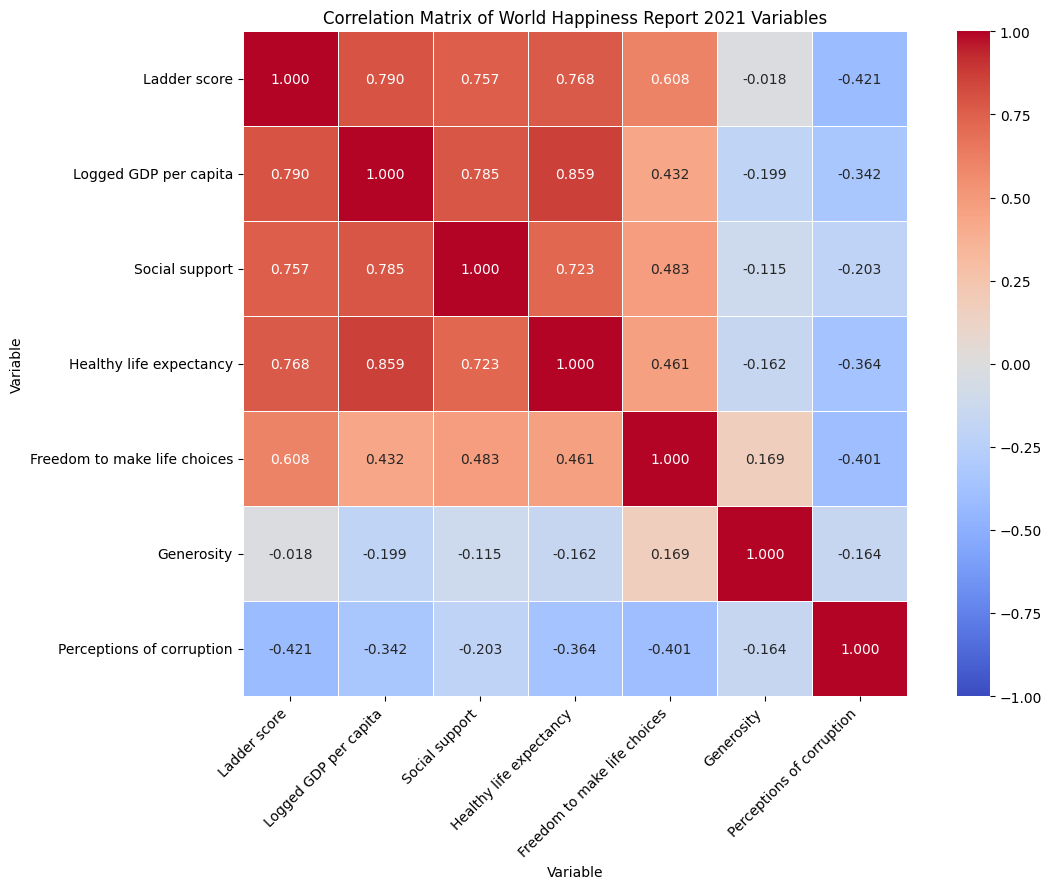

In [ ]:
correlation_matrix = data.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(3))

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title(
    "Correlation Matrix of World Happiness Report 2021 Variables"
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

The first five variables (Ladder score, Logged GDP per capita,  Social support, Healthy life expectancy, Freedom to make life choices) appear to have relatively strong positive correlation with each other. Meanwhile Generosity has a weak postive relation with free to make life choices, but has negative relationship with the rest of the variables. Perceptions of corruption has a negative relationship with all other variables.

Healthy Life Expectancy and Logged GDP per capita have the strongest postive correlation with correlation = 0.859. After that is Ladder Score and Logged GDP per Capita with correlation = 0.790.

Ladder Score and Perceptions of Corruption have a relatively strong negative correlation with correlation = -0.421. Freedom to Make Life Choices and Perceptions of Corruption also have a relatively strong negative correlation with correlation = -0.401.

Part B – Principal Component Analysis (12 points)
Using the standardized variables:
1. Conduct PCA using the correlation matrix. (2 pts)
2. Report the eigenvalues of the seven principal components. (2 pts)
3. Report the proportion of variance explained by each component. (2 pts)
4. Report the cumulative proportion of variance explained. (2 pts)
5. Present the eigenvectors/component coefficients for the retained components. (2 pts)
6. Identify which variables have the largest absolute coefficients in the first principal component. (2 pts)

In [ ]:
pca = PCA()
pca.fit(standardized_data)

eigenvalues = pca.explained_variance_
prop_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(prop_var)

pc_names = [f"PC{i+1}" for i in range(len(eigenvalues))]

pca_summary = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Proportion of Variance": prop_var,
    "Cumulative Proportion": cumulative_var
}, index=pc_names)

print("PCA Variance Summary:")
display(pca_summary.round(3))

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(variables))],
    index=variables
)
print("\nEigenvectors / Component Coefficients:")
display(loadings.round(3))

PCA Variance Summary:


,Eigenvalue,Proportion of Variance,Cumulative Proportion
PC1,3.940,0.559,0.559
PC2,1.298,0.184,0.743
PC3,0.713,0.101,0.844
PC4,0.522,0.074,0.918
PC5,0.253,0.036,0.954
PC6,0.195,0.028,0.982
PC7,0.127,0.018,1.000



Eigenvectors / Component Coefficients:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Ladder score,0.464,0.040,0.088,-0.013,0.095,0.869,-0.105
Logged GDP per capita,0.459,-0.197,-0.002,-0.256,-0.174,-0.124,0.800
Social support,0.433,-0.163,0.324,-0.087,0.704,-0.361,-0.218
Healthy life expectancy,0.453,-0.146,-0.032,-0.230,-0.612,-0.234,-0.539
Freedom to make life choices,0.341,0.365,0.167,0.811,-0.163,-0.174,0.092
Generosity,-0.042,0.753,0.466,-0.449,-0.083,-0.051,0.041
Perceptions of corruption,-0.252,-0.460,0.801,0.119,-0.238,0.107,0.037


The variables with the largest absolute coefficients in PC1 are:
Ladder score (0.464053)
Logged GDP per capita	(0.459118)
Healthy life expectancy	(0.453028)


Part C – Determining the Number of Components (10 points)
1. Construct a scree plot of the eigenvalues. (3 pts)

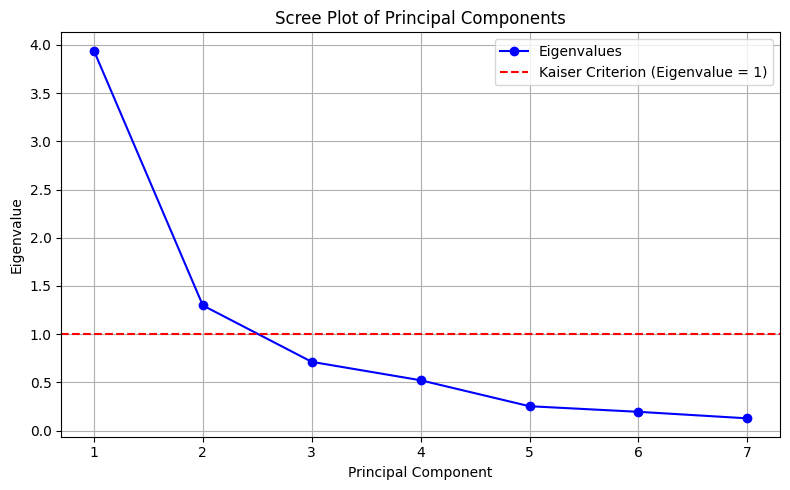

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', color='b', label='Eigenvalues')
plt.axhline(y=1, color='r', linestyle='--', label='Kaiser Criterion (Eigenvalue = 1)')
plt.title('Scree Plot of Principal Components')
plt.xlabel('Principal Component')
plt.ylabel('Eigenvalue')
plt.xticks(range(1, len(eigenvalues) + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

2. Identify the apparent elbow in the scree plot. (2 pts)
> Based on the scree plot generated, the apparent elbow, or the point
where the downward curve bends and turns nearly flat, is PC3. We can see that the line drops sharply from PC1 to PC2, and then the line starts to leve out at PC3.

3. Apply the Kaiser criterion by identifying components with eigenvalues greater than 1. (2 pts)
> Looking at the eigenvalues generated in Part B and the scree plot, only PC1 and PC2 have eigenvalues greater than 1.

4. Based on the scree plot, eigenvalues, and cumulative variance explained, determine an appropriate number of components to retain. (2 pts)
> Based on all three criteria, the appropriate number of components to retain is two. The elbow is at PC3 and only PC1 and PC2 have eigenvalues greater than 1. Along with that PC1 and PC2 manage to explain 74.3% of total variance.

5. Briefly explain why the number of components retained should not be determined using only one criterion. (1 pt)
> This is because each criteria have their downsides. The elbow of scree plots are subjective, one can argue that the elbow is PC2 or Pc3 or PC4. Meanwhile using Kaiser criterion may lead to overestimating or underestimating number of components , and using cumulative variance means picking an arbitrary threshold like 75% or 90%. Thus, it is better to look at all criteria in order to achieve a sound reduction.

Part D – Interpretation of Principal Components (10 points)
Based on your PCA output:

1. Interpret Principal Component 1 (PC1) in terms of the variables with the largest positive or negative coefficients. (3 pts)
> PC1 has strong positive coefficients for Ladder score (0.464), Logged GDP per capita (0.459), Healthy life expectancy (0.453), and Social support (0.433). PC1 seems to be associated with overall happiness and socioeconomic well-being. Countries with high scores in this component, have higher ladder scores, greater Logged GDP per capita, stronger social support, longer Healthy life expectancy, and more Freedom to make life choices.

2. Interpret Principal Component 2 (PC2) in the same manner. (2 pts)
> PC2 has positive coefficients for Generosity (0.753), a moderate positive coefficient for Freedom to make life choices (0.365) and a strong negative coefficient for Perceptions of corruption (-0.460). This component reflects the contrast between generosity and freedom/perceptions of corruption.

3. Give an appropriate descriptive name or label for PC1 based on its variable loadings and explain your choice. (2 pts)
> I would choose General Well-being and Quality of Life as the label for PC1 as it has relatively strong positive loadings for Ladder Score (0.464), Logged GDP per Capita (0.459), Healthy Life Expectancy (0.453), and Social Support (0.433). These variables represent happiness, economic prosperity, health, ND social relationships, which are all factors that make up well-being and quality of life in countries. Thus, PC1 captures the overall well-being and quality of life across countries.

4. Explain how many original variables can potentially be represented by the retained components. (1 pt)
> All of the seven original variables can potentially be represented by the two retained components. In PC1, four variables—Ladder Score, Logged GDP per Capita, Healthy Life Expectancy, and Social Support—have strong positive coefficients. Meanwhile in PC2, the three remaining variables—Freedom to Make Life Choices, Generosity and Perceptions of Corruption—have strong/moderately strong coefficents.

5. Write a short conclusion explaining what PCA reveals about the underlying dimensions of cross-country well-being in this dataset. (2 pts)
> The PCA reveals that cross-country well-being may be summarized  through two dimensions. The first dimension named General Well-being and Quality of Life, captures the combined influence of Ladder Score, Logged GDP per Capita, Healthy Life Expectancy, and Social Support. The second dimension, highlights another aspect of well-being involving Freedom to Make Life Choices, Generosity and Perceptions of Corruption.
>
> PC1 and PC2 manage to represent all 7 variables of cross-country well-being and preserve 74.3% of total variation, while reducing the features into a more manageable number. Overall, the results show that cross-country well-being cannot be determined by a single inidcator  but it involves several interconnected socioeconomic and social factors.